**CodSoft Task 5 - Credit Card Fraud Detection**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score,f1_score,classification_report

from imblearn.over_sampling import SMOTE


df=pd.read_csv('/content/creditcard.csv')
print(df.head())
print(df.shape)


   Time        V1        V2        V3  ...       V27       V28  Amount  Class
0   0.0 -1.359807 -0.072781  2.536347  ...  0.133558 -0.021053  149.62      0
1   0.0  1.191857  0.266151  0.166480  ... -0.008983  0.014724    2.69      0
2   1.0 -1.358354 -1.340163  1.773209  ... -0.055353 -0.059752  378.66      0
3   1.0 -0.966272 -0.185226  1.792993  ...  0.062723  0.061458  123.50      0
4   2.0 -1.158233  0.877737  1.548718  ...  0.219422  0.215153   69.99      0

[5 rows x 31 columns]
(284807, 31)


In [6]:
print('Dataset information')
print(df.info())

Dataset information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  flo

In [7]:
print('Missing Values:')
print(df.isnull().sum())

Missing Values:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [9]:
print('Transaction Class Distribution:')
print(df['Class'].value_counts())

Transaction Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [10]:
print('Percentage Distribution:')
print(df['Class'].value_counts(normalize=True)*100)

Percentage Distribution:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


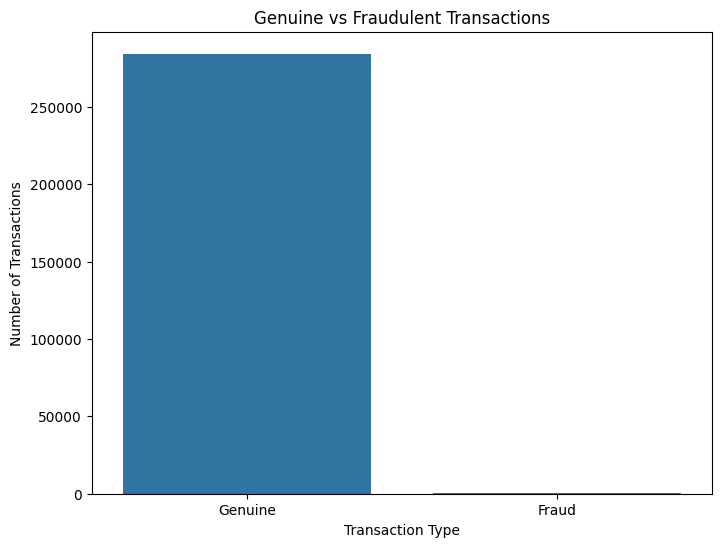

In [11]:
plt.figure(figsize=(8,6))
sns.countplot(x='Class',data=df)
plt.title('Genuine vs Fraudulent Transactions')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')
plt.xticks([0,1],['Genuine','Fraud'])
plt.show()

In [12]:
X=df.drop('Class',axis=1)
y=df['Class']

print('Features shape:', X.shape)
print('Target shape:', y.shape)



Features shape: (284807, 30)
Target shape: (284807,)


In [14]:
X_train,X_test,y_train,y_test=train_test_split(X_scaled,y,test_size=0.2,random_state=42)
print('Training data',X_train.shape)
print('Testing data',X_test.shape)

Training data (227845, 30)
Testing data (56962, 30)


In [15]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

print('data normalization completed successfully!!')

data normalization completed successfully!!


In [16]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print('Before applying SMOTE')
print(y_train.value_counts())

print('After applying SMOTE')
print(y_train_resampled.value_counts())

Before applying SMOTE
Class
0    227451
1       394
Name: count, dtype: int64
After applying SMOTE
Class
0    227451
1    227451
Name: count, dtype: int64


In [18]:
model=LogisticRegression(max_iter=1000,random_state=42)
model.fit(X_train_resampled,y_train_resampled)

print('Logistic Regression model trained successfully!!')

y_pred=model.predict(X_test)
print('Predictions completed successfully!!')

Logistic Regression model trained successfully!!
Predictions completed successfully!!


In [21]:
accuracy=model.score(X_test,y_test)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print('Model Performance')
print('----------------------')
print('Accuracy:',accuracy)
print('Precision:',precision)
print('Recall:',recall)
print('F1 Score:',f1)



Model Performance
----------------------
Accuracy: 0.9745795442575752
Precision: 0.058823529411764705
Recall: 0.9183673469387755
F1 Score: 0.11056511056511056


In [22]:
print('\nClassification Report')
print(classification_report(y_test,y_pred))


Classification Report
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962



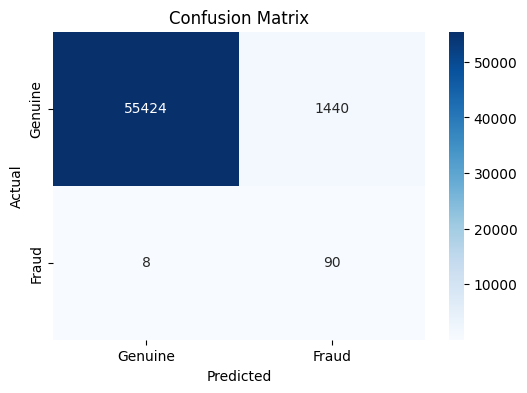

In [25]:
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Genuine", "Fraud"],
    yticklabels=["Genuine", "Fraud"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [27]:
results=pd.DataFrame({'Metric':['Accuracy','Precision','Recall','F1 Score'],'Score':[accuracy,precision,recall,f1]})

print('Final Model Performance')
print('-------------------------')
print(f'Accuracy: {accuracy:.2f}')
print(f'Precision: {precision:.2f}')
print(f'Recall: {recall:.2f}')
print(f'F1 Score: {f1:.2f}')

Final Model Performance
-------------------------
Accuracy: 0.97
Precision: 0.06
Recall: 0.92
F1 Score: 0.11


In this project, a Logistic Regression model was developed to detect fraudulent credit card transactions. The data was preprocessed and normalized, and the class imbalance was handled using SMOTE. The model was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. The results show the model's ability to identify fraudulent transactions while distinguishing them from genuine transactions.